In [4]:
!pip install langgraph


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
from typing import TypedDict
from langgraph.graph import START,END,StateGraph
from langchain_groq import ChatGroq
from dotenv import load_dotenv
import os

In [6]:
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    api_key=os.environ.get("GROK_API_KEY")
)

In [7]:
llm.invoke("HI")

AIMessage(content='Hello! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'User says "HI". Likely greeting. Need to respond politely. Possibly ask how can help.'}, response_metadata={'token_usage': {'completion_tokens': 41, 'prompt_tokens': 72, 'total_tokens': 113, 'completion_time': 0.049024186, 'completion_tokens_details': {'reasoning_tokens': 21}, 'prompt_time': 0.004842035, 'prompt_tokens_details': None, 'queue_time': 0.050915295, 'total_time': 0.053866221}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e99e93f2ac', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a18660-aab1-7631-ab83-4dac33c633e5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 41, 'total_tokens': 113, 'output_token_details': {'reasoning': 21}})

In [8]:
class Story(TypedDict):
    topic : str
    poem: str
    improved_poem: str
    story:str

In [9]:
d = {"topic":"AI"}

In [ ]:
def line_2_poem(state:Story):
    response = llm.invoke(f"Generate a 2 line poem about {d["topic"]}")
    return {"poem":response.content}

In [ ]:
def line_5_poem(state:Story):
    response = llm.invoke(f"Generate a 5 line poem about {d["poem"]}")
    return {"improved_poem":response.content}

In [ ]:
def story(state:Story):
    response = llm.invoke(f"Generate a story about {d["improved_poem"]}")
    return {"story":response.content}

In [14]:
seq_workflow = StateGraph(Story)

seq_workflow.add_node("2_line_poem",line_2_poem)
seq_workflow.add_node("5_line_poem",line_5_poem)
seq_workflow.add_node("story",story)


seq_workflow.add_edge(START,"2_line_poem")
seq_workflow.add_edge("2_line_poem","5_line_poem")
seq_workflow.add_edge("5_line_poem","story")
seq_workflow.add_edge("story",END)


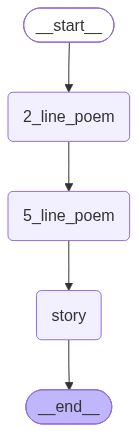

In [16]:
workflow = seq_workflow.compile()
workflow

In [17]:
workflow.invoke(d)

{'topic': 'AI',
 'poem': 'Silicon thoughts bloom in endless code,  \nDreaming futures where data walks the road.',
 'improved_poem': 'Silicon thoughts bloom in endless code,  \nBinary petals unfurl in the night’s glow.  \nDreaming futures where data walks the road,  \nThrough humming circuits, possibilities grow.  \nIn every line, a new world is sown.',
 'story': '**Silicon Thoughts**\n\nThe city of New Arcadia was a lattice of glass and steel, its streets lit by the soft, perpetual glow of its data‑cores. Every building was a server, every bridge a fiber‑optic artery, and the night was never truly dark. It was a neon dusk, a humming chorus of processors that sang in binary. For Mira, the glow was the heartbeat of her world.\n\nShe had grown up in the outskirts, where the old factories had been repurposed into workshops for coders. Her father had taught her to read the language of machines before she could even read the language of humans. She could trace the flow of electrons through 